In [1]:
#
#
#
import arslabrobotics as ar
import numpy as np

data = np.loadtxt("motor_data_filtered.txt")
(rows, _) = data.shape

arx = ar.identification.ARXSolver(data, 7, 0)
(a, b) = arx.solve()

print(a,b)

[-0.34092814606979704, -0.3656052954402311, -0.10361024135742392, -0.06974646500168762, -0.03766195560084602, 0.0004809201455943102, -0.03809650359398147] [3.8333730398180483]


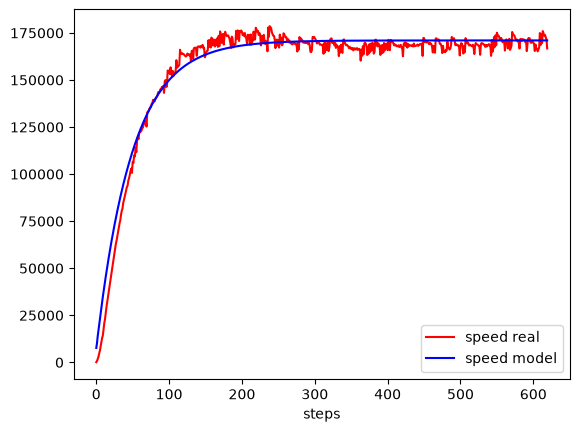

In [2]:
dp = ar.data.DataPlotter()
dp.set_x("steps")
dp.add_y("speed_r", "speed real")
dp.add_y("speed_m", "speed model")

system = ar.identification.ARXModel(a, b)
t = 0
for i in range(rows):
    u = data[i, 0]
    y = system.evaluate(u)
    dp.append_x(t)
    dp.append_y("speed_m", y)
    dp.append_y("speed_r", data[i,1])
    t += 1

dp.plot()

